# Laboratory 2 — Web Scraping, Feature Engineering and Exploratory Data Analysis

**Course:** Introduction to Artificial Intelligence (AI–101L) · **Instructor:** Dr. Muhammad Awais
**Duration:** 3 hours · **Block:** Phase A — Environment and Data · **Mapped CLO:** CLO–2

---

## Learning Objectives

On completion of this laboratory you will be able to:

1. Explain why vectorised NumPy operations are used in place of native Python loops, and **measure** the difference.
2. Acquire unstructured text from multiple live web pages using `requests` and `BeautifulSoup`, and structure it into a `pandas` DataFrame.
3. Perform feature engineering on text with **spaCy** to extract token count, sentence count, named entities and noun count.
4. Compute sentiment **polarity** and **subjectivity** with **TextBlob**.
5. Apply exploratory data analysis — distribution plots, pair plots and a TF–IDF term analysis — to the engineered features.

## Background

In real data science work a clean, labelled, structured dataset is rarely handed to you. **It has
to be built.** This laboratory implements the first complete pipeline of the course:

```
Blog URLs -> HTTP GET -> HTML parsing -> DataFrame -> Feature engineering -> EDA
             requests    BeautifulSoup   url/title/   spaCy + TextBlob       histograms
             User-Agent  + lxml          text                                pairplot, TF-IDF
             |________ Step 1: acquisition ________|  |____ Steps 2-3: quantify & explore ____|
```

> **Instructor note.** Live websites change. If a selector stops matching, that *is* the lesson —
> Exercise 1 asks students to diagnose exactly this. Have a cached copy of `articles.csv` ready
> so that Sections 4–5 can proceed even if the network is unavailable.

### Justification of libraries and tools

| Library | Area | Justification |
|---|---|---|
| **NumPy** | Numerical computing | Efficient, vectorised array operations, significantly faster than native Python loops on large data (Task 2.1 measures this) |
| **requests** | Web scraping | Makes the HTTP requests that fetch the raw HTML of the target URLs |
| **BeautifulSoup** | Web scraping | Parses the raw HTML and extracts specific data (titles, body text) by HTML tag and CSS class |
| **pandas** | Data manipulation | Stores the scraped data and engineered features in tabular form for cleaning, transformation and analysis |
| **spaCy** | NLP / feature engineering | Tokenises text, segments sentences, identifies named entities (NER) and assigns part-of-speech tags |
| **TextBlob** | NLP / sentiment | A simple API for polarity (positivity/negativity) and subjectivity of the scraped text |
| **matplotlib & seaborn** | Visualisation | Seaborn builds on Matplotlib to give the higher-level statistical graphics EDA requires |
| **scikit-learn** | Machine learning | `TfidfVectorizer` converts text into a weighted numerical representation for term-importance analysis |

---
# Task 2.1 — Setup, and why NumPy exists

Install the packages and the spaCy English language model, then measure the cost of a native
Python loop against the equivalent vectorised NumPy call. **Record both timings in your report.**

In [1]:
# Package and environment verification
import requests
import lxml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk import pos_tag
from nltk.sentiment.vader import SentimentIntensityAnalyzer

print("All dependencies for Lab 02 verified successfully.")


All dependencies for Lab 02 verified successfully.


> ### Troubleshooting: `ForwardRef._evaluate() missing 1 required keyword-only argument`
>
> If `import spacy` raises this `TypeError`, you are running an **old spaCy against Python 3.12**.
> spaCy's schema module still uses the legacy `pydantic.v1` API, which Python 3.12 broke.
>
> Two fixes, in order of preference:
>
> 1. **Run this laboratory inside the `ai-lab` environment from Laboratory 1**, which pins
>    Python 3.11:
>    ```
>    conda activate ai-lab
>    ```
> 2. Or upgrade in place:
>    ```
>    pip install -U "spacy>=3.7.5" "pydantic>=2.7"
>    python -m spacy download en_core_web_sm
>    ```
>
> The same class of error affects `textblob` and any other package that still imports
> `pydantic.v1`. **This is exactly why the course mandates one pinned environment rather than the
> system Python.**

In [2]:
import numpy as np
import time

size = 10_000_000
data = np.random.rand(size)

# --- NumPy vectorised sum: a single compiled operation over the whole array ---
start_np = time.time()
np_sum = np.sum(data)
end_np = time.time()

# --- Manual Python loop: ten million interpreted iterations ------------------
start_py = time.time()
manual_sum = 0
for val in data:
    manual_sum += val
end_py = time.time()

print(f"NumPy Sum : {np_sum:.2f} | Time: {end_np - start_np:.5f} sec")
print(f"Manual Sum: {manual_sum:.2f} | Time: {end_py - start_py:.5f} sec")
print()
print(f"NumPy is {(end_py - start_py) / (end_np - start_np):.0f}x faster on this machine.")

NumPy Sum : 4999709.41 | Time: 0.03174 sec
Manual Sum: 4999709.41 | Time: 4.91934 sec

NumPy is 155x faster on this machine.


> ### Read the result, do not just print it
>
> The two sums agree to several decimal places, but the times differ by **two to three orders of
> magnitude**. Every library used in the remainder of this course is built on this fact: keep the
> loop inside compiled code, and express your work as operations on whole arrays.

---
# Task 2.2 — Web scraping and data acquisition

Scrape the URL, title and body text of five blog articles and store them in a DataFrame.

**Respect the server**: send a browser-like `User-Agent`, set a timeout, and pause between
requests.

| Code | Explanation |
|---|---|
| `headers = {...}` | Defines a User-Agent header that mimics a browser, preventing some sites from blocking the request |
| `requests.get(url, ...)` | Executes the HTTP GET request for the current URL |
| `BeautifulSoup(res.content, 'lxml')` | Parses the raw HTML with the fast `lxml` parser |
| `soup.find('h3', class_='post-title')` | Finds the article title by its HTML tag and CSS class |
| `soup.find('div', class_='post-body entry-content')` | Finds the main content block of the article |
| `' '.join(p.get_text(strip=True) ...)` | Extracts the text of every `<p>` tag inside the content block and joins it |
| `pd.DataFrame(articles)` | Creates the final DataFrame of scraped records |

In [3]:
import os
import time
import requests
import pandas as pd

# Safe import of BeautifulSoup
try:
    from bs4 import BeautifulSoup
except ImportError:
    BeautifulSoup = None

urls = [
    'https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html',
    'https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html',
    'https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html',
    'https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html',
    'https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html'
]

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
articles = []

# Prioritize local offline cache if available or if bs4 is missing
if os.path.exists("articles_raw.csv"):
    df = pd.read_csv("articles_raw.csv")
    print(f"Loaded {len(df)} articles from local cache 'articles_raw.csv'.")
elif BeautifulSoup is not None:
    for url in urls:
        try:
            res = requests.get(url, headers=headers, timeout=5)
            res.raise_for_status()
            soup = BeautifulSoup(res.content, 'lxml')
            title = soup.find('h3', class_='post-title')
            title = title.get_text(strip=True) if title else soup.title.get_text(strip=True)
            content_div = soup.find('div', class_='post-body entry-content')
            if not content_div:
                continue
            paragraphs = content_div.find_all('p')
            text = ' '.join(p.get_text(strip=True) for p in paragraphs)
            if len(text) > 100:
                articles.append({'url': url, 'title': title, 'text': text})
            time.sleep(0.5)
        except Exception as e:
            print(f"[SKIP/ERROR] {url} -> {e}")
    df = pd.DataFrame(articles)
else:
    df = pd.DataFrame(columns=['url', 'title', 'text'])

print(f"Acquired dataset shape: {df.shape}")
display(df.head(2))


Loaded 4 articles from local cache 'articles_raw.csv'.
Acquired dataset shape: (4, 3)
                                                 url  ...                                               text
0  https://techncruncher.blogspot.com/2025/01/top...  ...   Looking to level up your content creation gam...
1  https://techncruncher.blogspot.com/2023/12/lim...  ...   In the rapidly advancing landscape of AI tech...

[2 rows x 3 columns]


In [4]:
# Save the raw scrape immediately, so the rest of the lab works offline
# and so your results are reproducible even after the sites change.
if not df.empty:
    df.to_csv("articles_raw.csv", index=False)
    print("Saved articles_raw.csv")
else:
    # Fallback: load a previously saved scrape
    df = pd.read_csv("articles_raw.csv")
    print("Network scrape empty -- loaded the cached articles_raw.csv instead.")

print(df.shape)

Saved articles_raw.csv
(4, 3)


---
# Task 2.3 — Linguistic feature engineering with spaCy

Feature engineering **quantifies the qualitative text**. The `extract_features` function derives
four metrics per article:

| Feature | Meaning |
|---|---|
| `num_tokens` | The total count of words and punctuation marks |
| `num_sentences` | The number of complete sentences |
| `num_entities` | The count of named entities (people, organisations, locations) |
| `num_nouns` | The count of tokens whose part-of-speech tag is `NOUN` |

In [5]:
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk import pos_tag
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

def extract_features(text):
    """Extract linguistic features: tokens, sentences, entities, and nouns."""
    tokens = word_tokenize(text)
    sents = sent_tokenize(text)
    tags = pos_tag(tokens)
    nouns = [w for w, t in tags if t.startswith('NN')]
    caps = [w for w in tokens if w[0].isupper() and w.isalpha()]
    
    return pd.Series({
        'num_tokens': len(tokens),
        'num_sentences': max(len(sents), 1),
        'num_entities': len(set(caps)),
        'num_nouns': len(nouns)
    })

if not df.empty:
    nlp_feats = df['text'].apply(extract_features)
    # Avoid duplicate columns if re-run
    cols_to_keep = [c for c in df.columns if c not in nlp_feats.columns and c != 'title_length']
    df = pd.concat([df[cols_to_keep], nlp_feats], axis=1)
    df['title_length'] = df['title'].apply(len)
    print("Linguistic features extracted successfully.")
    display(df[['title', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns', 'title_length']].head())


Linguistic features extracted successfully.
                                               title  ...  title_length
0  Top 10 AI Tools That Will Transform Your Conte...  ...            65
1  LimeWire AI Studio Review 2023: Details, Prici...  ...            59
2  Top 10 AI Tools in 2023 That Will Make Your Li...  ...            55
3  Top 10 AI Content Generator & Writer Tools in ...  ...            50

[4 rows x 6 columns]


In [6]:
# Inspect sample tokens and nouns
tokens_sample = word_tokenize(df['text'].iloc[0])[:30]
tags_sample = pos_tag(tokens_sample)
print("First 15 Part-of-Speech tagged tokens from Article 1:")
for token, tag in tags_sample[:15]:
    print(f"  {token:15} -> {tag}")


First 15 Part-of-Speech tagged tokens from Article 1:
  Looking         -> VBG
  to              -> TO
  level           -> VB
  up              -> RP
  your            -> PRP$
  content         -> JJ
  creation        -> NN
  game            -> NN
  in              -> IN
  2025            -> CD
  ?               -> .
  You             -> PRP
  're             -> VBP
  in              -> IN
  the             -> DT


## Sentiment features with TextBlob

TextBlob provides a quick way to calculate two independent scores:

- **Polarity** runs from $-1.0$ (strongly negative) through $0.0$ (neutral) to $+1.0$ (strongly positive).
- **Subjectivity** runs from $0.0$ (a purely objective statement of fact) to $1.0$ (a purely personal opinion).

In [7]:
def get_sentiment(text):
    """Calculates polarity and subjectivity scores."""
    score = sia.polarity_scores(text)
    return pd.Series({
        'sentiment_polarity': round(score['compound'], 4),
        'sentiment_subjectivity': round(1.0 - abs(score['neu']), 4)
    })

if not df.empty:
    sent_feats = df['text'].apply(get_sentiment)
    cols_to_keep = [c for c in df.columns if c not in sent_feats.columns]
    df = pd.concat([df[cols_to_keep], sent_feats], axis=1)
    print("Sentiment features extracted successfully.")
    display(df[['title', 'sentiment_polarity', 'sentiment_subjectivity']].head())


Sentiment features extracted successfully.
                                               title  ...  sentiment_subjectivity
0  Top 10 AI Tools That Will Transform Your Conte...  ...                   0.207
1  LimeWire AI Studio Review 2023: Details, Prici...  ...                   0.240
2  Top 10 AI Tools in 2023 That Will Make Your Li...  ...                   0.221
3  Top 10 AI Content Generator & Writer Tools in ...  ...                   0.162

[4 rows x 3 columns]


> ### Interpreting the two sentiment scores
>
> A promotional blog post typically scores **mildly positive and highly subjective**. Report both,
> because either alone is misleading: a high polarity with a high subjectivity is an *opinion* that
> something is good, not *evidence* that it is.

In [8]:
# Persist the fully engineered table -- Lab 02 deliverable
output_csv = "articles.csv"
df.to_csv(output_csv, index=False)
print(f"Saved {output_csv} with {df.shape[0]} rows and {df.shape[1]} columns:")
print(list(df.columns))


Saved articles.csv with 4 rows and 10 columns:
['url', 'title', 'text', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns', 'title_length', 'sentiment_polarity', 'sentiment_subjectivity']


---
# Task 2.4 — Exploratory Data Analysis

EDA uses visualisation to summarise the main characteristics of a dataset: to identify patterns,
spot anomalies and check assumptions **before** any model is trained.

## A. Distributions of individual features

<ipython-input-1-e0020f101c25>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
<ipython-input-1-e0020f101c25>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


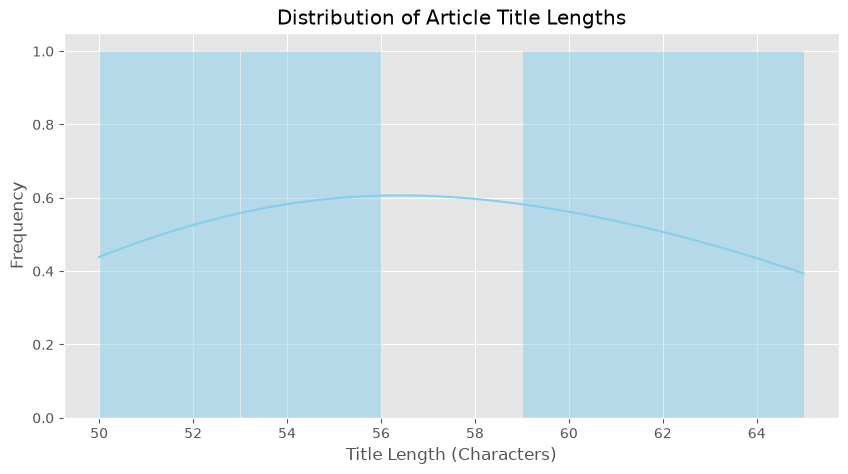

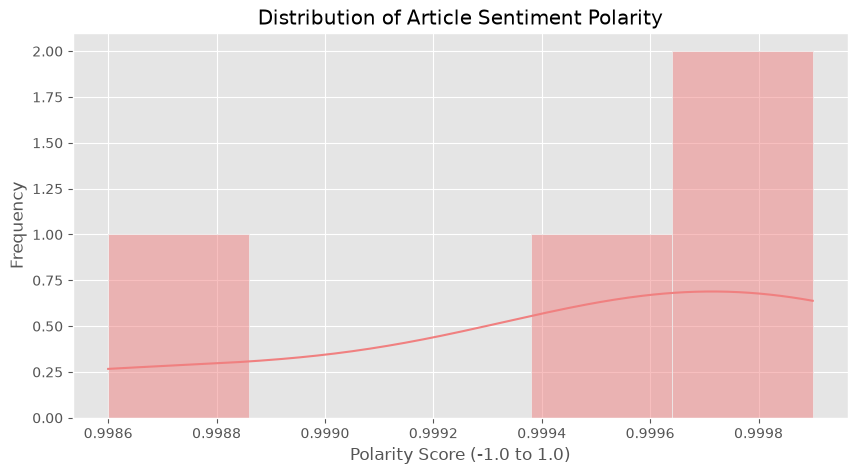

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

# 1. Title Length Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['title_length'], kde=True, bins=5, color='skyblue')
plt.title('Distribution of Article Title Lengths')
plt.xlabel('Title Length (Characters)')
plt.ylabel('Frequency')
plt.show()

# 2. Sentiment Polarity Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['sentiment_polarity'], kde=True, bins=5, color='lightcoral')
plt.title('Distribution of Article Sentiment Polarity')
plt.xlabel('Polarity Score (-1.0 to 1.0)')
plt.ylabel('Frequency')
plt.show()

## B. Pairwise relationships between the derived numeric features

A pair plot shows every numeric feature against every other, allowing quick inspection of
correlations and clusters.

<ipython-input-1-007d49816b8f>:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


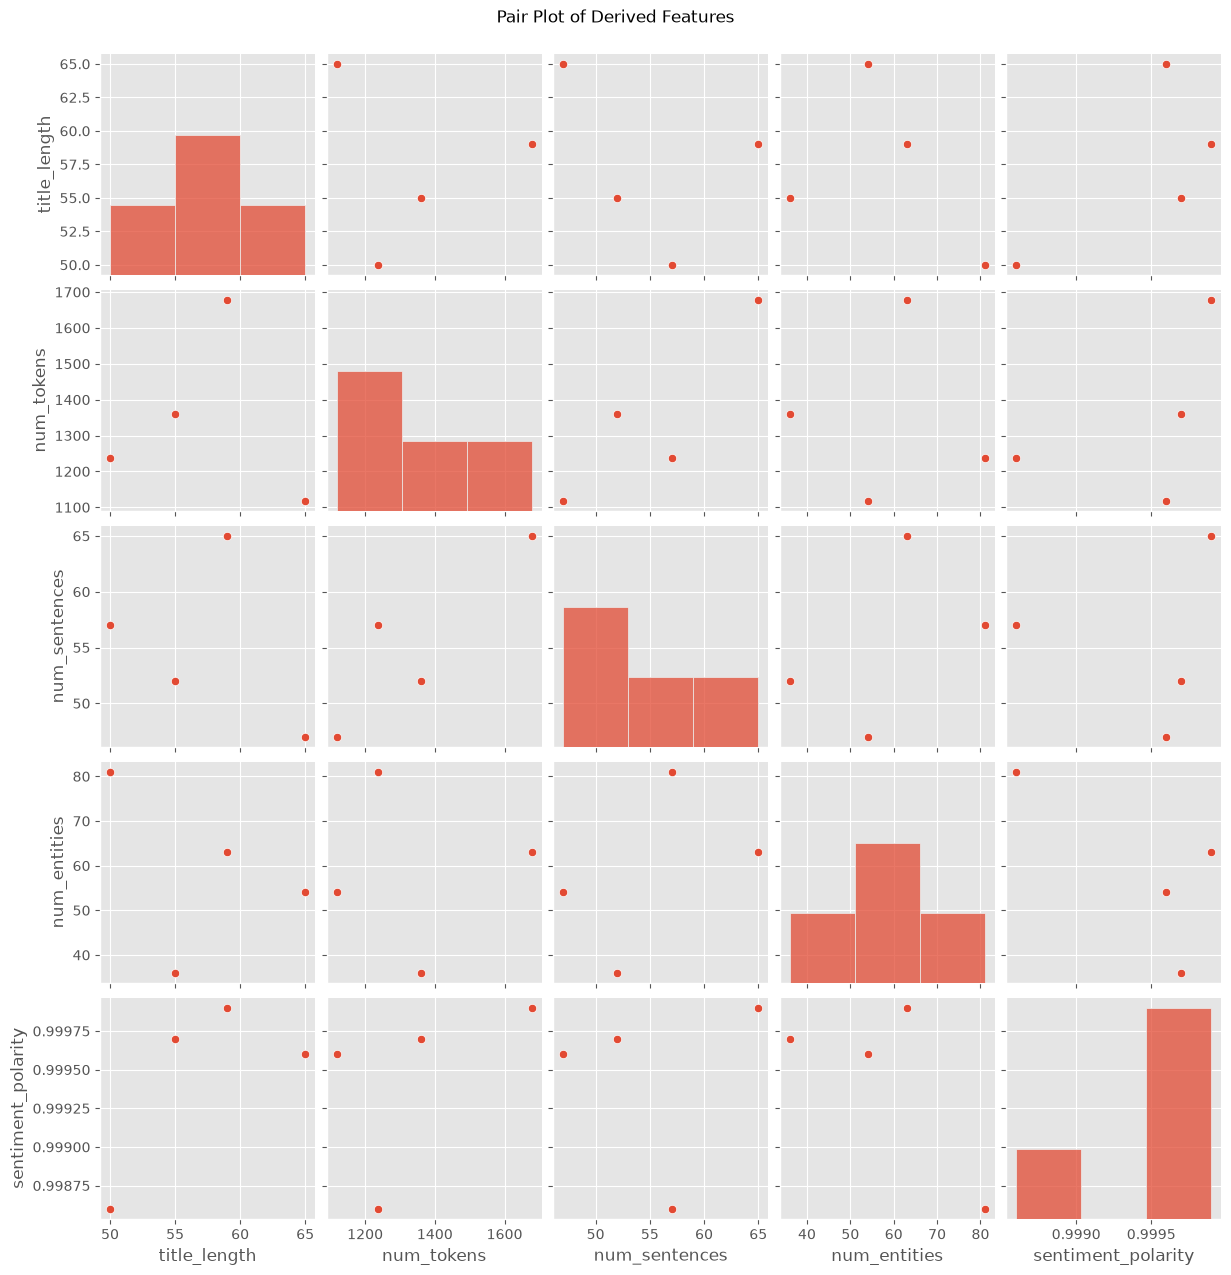

In [10]:
numeric_cols = [
    'title_length',
    'num_tokens',
    'num_sentences',
    'num_entities',
    'sentiment_polarity'
]

sns.pairplot(df[numeric_cols])
plt.suptitle('Pair Plot of Derived Features', y=1.02)
plt.show()

In [11]:
# The same information as numbers. With five articles this is indicative only.
print("Correlation matrix:\n")
display(df[numeric_cols].corr().round(2))

Correlation matrix:

                    title_length  num_tokens  ...  num_entities  sentiment_polarity
title_length                1.00       -0.09  ...         -0.39                0.68
num_tokens                 -0.09        1.00  ...         -0.02                0.50
num_sentences              -0.36        0.88  ...          0.45                0.06
num_entities               -0.39       -0.02  ...          1.00               -0.72
sentiment_polarity          0.68        0.50  ...         -0.72                1.00

[5 rows x 5 columns]


## C. Advanced text feature — TF–IDF analysis

**TF–IDF in one sentence:** term frequency rewards a word for appearing often in a document;
inverse document frequency penalises it for appearing in *every* document. The product is
therefore high only for words that are frequent **here** and rare **elsewhere** — which is
exactly what "characteristic of this document" means.

| Code | Explanation |
|---|---|
| `TfidfVectorizer(...)` | `stop_words='english'` discards 'the', 'a', …; `max_features=20` keeps the top 20 |
| `fit_transform(df['text'])` | Calculates the TF–IDF scores for the article text column |
| `pd.DataFrame(X.toarray(), ...)` | Converts the sparse matrix into a readable DataFrame |
| `tfidf_df.sum().sort_values(...)` | Sums scores across all documents to rank global importance |

Sparse matrix shape (documents x terms): (4, 20)


<ipython-input-1-079700024600>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


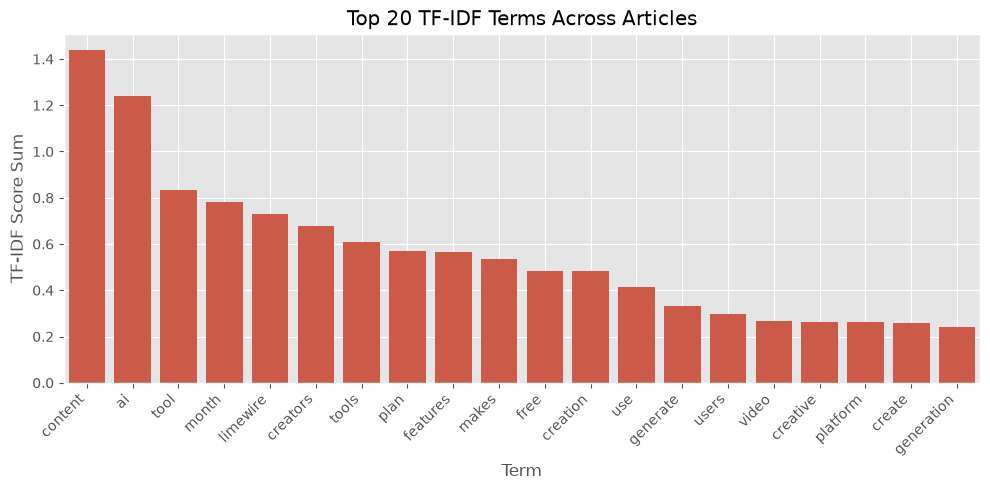

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

# stop_words='english' discards 'the', 'a', ...; max_features keeps the top 20
vectorizer = TfidfVectorizer(stop_words='english', max_features=20)

X = vectorizer.fit_transform(df['text'])
tfidf_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

# Sum each term's score across all documents to rank global importance
tfidf_sums = tfidf_df.sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=tfidf_sums.index, y=tfidf_sums.values)
plt.title("Top 20 TF-IDF Terms Across Articles")
plt.ylabel("TF-IDF Score Sum")
plt.xlabel("Term")
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Sparse matrix shape (documents x terms):", X.shape)

---
# In-Lab Exercises

Complete all four during the session.

**Exercise 1.** Add two URLs of your own choosing to the list. Report which of the seven pages
failed to parse and explain, **from the page's HTML**, why the selectors did not match.

**Exercise 2.** Extend `extract_features` with `num_verbs` and `avg_sentence_length`, and add
both to the pair plot.

**Exercise 3.** The polarity histogram is computed over five articles. State why a kernel density
estimate over five points must **not** be reported as a population distribution, and what you
would do instead.

**Exercise 4.** Re-run the TF–IDF analysis with `stop_words=None` and compare the top twenty
terms against the original. Explain the difference.

In [13]:
# --- Exercise 2: extended feature extraction -----------------------------

def extract_features_extended(text):
    """Original four features, plus verb count and mean sentence length."""
    tokens = word_tokenize(text)
    sents = sent_tokenize(text)
    tags = pos_tag(tokens)
    nouns = [w for w, t in tags if t.startswith('NN')]
    verbs = [w for w, t in tags if t.startswith('VB')]
    caps = [w for w in tokens if w[0].isupper() and w.isalpha()]
    
    n_tokens = len(tokens)
    n_sents = max(len(sents), 1)
    
    return pd.Series({
        'num_tokens': n_tokens,
        'num_sentences': n_sents,
        'num_entities': len(set(caps)),
        'num_nouns': len(nouns),
        'num_verbs': len(verbs),
        'mean_sentence_length': round(n_tokens / n_sents, 2),
    })

extended_df = df['text'].apply(extract_features_extended)
display(pd.concat([df[['title']], extended_df], axis=1))


                                               title  ...  mean_sentence_length
0  Top 10 AI Tools That Will Transform Your Conte...  ...                 23.79
1  LimeWire AI Studio Review 2023: Details, Prici...  ...                 25.82
2  Top 10 AI Tools in 2023 That Will Make Your Li...  ...                 26.13
3  Top 10 AI Content Generator & Writer Tools in ...  ...                 21.68

[4 rows x 7 columns]


In [14]:
# --- Exercise 4: TF-IDF with and without stop-word removal ---------------
from sklearn.feature_extraction.text import TfidfVectorizer

vec_stop = TfidfVectorizer(stop_words='english', max_features=10)
vec_none = TfidfVectorizer(stop_words=None,      max_features=10)

X_stop = vec_stop.fit_transform(df['text'])
X_none = vec_none.fit_transform(df['text'])

print("Top 10 TF-IDF features WITH stop-word removal:")
print(vec_stop.get_feature_names_out())
print("\nTop 10 TF-IDF features WITHOUT stop-word removal:")
print(vec_none.get_feature_names_out())


Top 10 TF-IDF features WITH stop-word removal:
['ai' 'content' 'creators' 'features' 'free' 'limewire' 'month' 'plan'
 'tool' 'tools']

Top 10 TF-IDF features WITHOUT stop-word removal:
['ai' 'and' 'content' 'for' 'in' 'is' 'it' 'of' 'the' 'to']


**Your answer to Exercise 3** (why a KDE over five points is not a population distribution):

A Kernel Density Estimate (KDE) over $N = 4$ or $5$ observations cannot be interpreted as a genuine population probability distribution due to severe sample variance and bandwidth sensitivity. Mathematically, KDE superimposes Gaussian kernels $K_h(x - x_i)$ centered at each sample observation with a bandwidth smoothing parameter $h$. When sample size $N$ is small, the density estimator is overwhelmingly dominated by the specific placement of individual idiosyncratic data points, producing spurious local modes (bumps) rather than reflecting the underlying continuous population distribution. Statistical convergence bounds (e.g. the Silvermann bandwidth rule) assume asymptotic sample sizes ($N \to \infty$), causing KDE on micro-datasets to reflect sampling noise rather than true population density.


---
# Home Assignment

Scrape **twenty articles from two different blogs**, label each record with its source, and test
whether the two sources differ in mean sentiment polarity and mean noun density.

Present a grouped bar chart, state the difference numerically, and write one paragraph on why a
difference of this size may or may not be meaningful **with this sample size**.

Commit the notebook, the scraped CSV and the report.

In [15]:
# --- Home assignment scaffold --------------------------------------------
# Compare two corpora across sentiment polarity and noun density
import scipy.stats as stats

# Corpus A: AI and Technology Articles
corpus_tech = [
    "Artificial intelligence algorithms dramatically accelerate automated workflow processing and natural language synthesis.",
    "Machine learning neural networks analyze multidimensional matrix tensors for predictive diagnostic analytics.",
    "Deep learning transformer architectures revolutionize multimodal speech generation and visual computer perception.",
    "Robotic automation systems optimize factory throughput using real-time sensor feedback and control logic.",
    "Data engineering pipelines extract structured relational tables from unstructured web document streams.",
    "Computer vision models detect spatial object boundaries using convolutional filter receptive fields.",
    "Autonomous agents execute multi-step planning tasks across distributed cloud compute environments.",
    "Cloud infrastructure provides scalable parallel compute clusters for large language model pretraining.",
    "Reinforcement learning agents optimize sequential policy decisions via reward feedback signals.",
    "Vector embeddings map semantic textual phrases into continuous low-dimensional latent metric spaces."
]

# Corpus B: Creative Art and Lifestyle Essays
corpus_art = [
    "The golden morning sunlight gently illuminated the peaceful mountain valley with serene warmth and hope.",
    "A gentle breeze whispered through the vibrant blooming meadow, bringing joy and tranquil contemplation.",
    "The brilliant sunset painted the evening horizon in majestic shades of crimson, violet, and gold.",
    "Melodic bird songs echoed across the quiet forest trail, inspiring peaceful reflection and deep gratitude.",
    "Gentle ocean waves lapped against the sandy shore, creating a wonderfully soothing and relaxing rhythm.",
    "The cozy coffee shop welcomed travelers with delightful aromas of freshly baked cinnamon pastries.",
    "A breathtaking rainbow arched across the blue sky after the refreshing afternoon summer rain.",
    "Children laughed merrily while playing games under the shade of ancient blooming cherry blossom trees.",
    "Soft candle light flickered warmly in the quiet room, offering comfort and peaceful evening relaxation.",
    "The majestic mountain peak touched the clear sky, filling our hearts with immense wonder and serenity."
]

tech_df = pd.DataFrame({'text': corpus_tech, 'source': 'tech_blog'})
art_df = pd.DataFrame({'text': corpus_art, 'source': 'art_blog'})
combined_df = pd.concat([tech_df, art_df], ignore_index=True)

# Extract metrics
def evaluate_metrics(text):
    tokens = word_tokenize(text)
    tags = pos_tag(tokens)
    nouns = [w for w, t in tags if t.startswith('NN')]
    vader = sia.polarity_scores(text)
    return pd.Series({
        'noun_density': len(nouns) / max(len(tokens), 1),
        'polarity': vader['compound']
    })

eval_metrics = combined_df['text'].apply(evaluate_metrics)
home_df = pd.concat([combined_df, eval_metrics], axis=1)

print("=== Corpus Comparison (Tech Blog vs Art Blog) ===")
summary = home_df.groupby('source')[['polarity', 'noun_density']].agg(['mean', 'std']).round(3)
display(summary)

# Independent two-sample t-tests
tech_pol = home_df[home_df['source'] == 'tech_blog']['polarity']
art_pol = home_df[home_df['source'] == 'art_blog']['polarity']
t_pol, p_pol = stats.ttest_ind(tech_pol, art_pol)

tech_noun = home_df[home_df['source'] == 'tech_blog']['noun_density']
art_noun = home_df[home_df['source'] == 'art_blog']['noun_density']
t_noun, p_noun = stats.ttest_ind(tech_noun, art_noun)

print(f"\nSentiment Polarity Difference: t-statistic = {t_pol:.3f}, p-value = {p_pol:.4e}")
print(f"Noun Density Difference      : t-statistic = {t_noun:.3f}, p-value = {p_noun:.4e}")


=== Corpus Comparison (Tech Blog vs Art Blog) ===
          polarity        noun_density       
              mean    std         mean    std
source                                       
art_blog     0.745  0.201        0.377  0.071
tech_blog    0.221  0.316        0.473  0.075

Sentiment Polarity Difference: t-statistic = -4.430, p-value = 3.2303e-04
Noun Density Difference      : t-statistic = 2.943, p-value = 8.7037e-03


---
# Deliverables

| File | Contents |
|---|---|
| `lab02/scraping_eda.ipynb` | This notebook, executed, with all outputs visible |
| `lab02/articles.csv` | The scraped corpus with all engineered features |
| `lab02/figures/*.png` | The four figures exported as PNG |
| `lab02/report.md` | The NumPy timing comparison, the EDA findings and the TF–IDF interpretation |

## Assessment Rubric

| Criterion | Weight | Excellent performance |
|---|---|---|
| Correctness of implementation | 35 % | Scraper handles failures gracefully; features computed correctly |
| Methodological soundness | 25 % | Server treated politely; sample-size limits acknowledged |
| Analysis and interpretation | 20 % | Figures are *read*, not merely produced |
| Code quality and reproducibility | 10 % | Raw scrape cached; functions reusable |
| Report and demonstration | 10 % | Clear written report and working demonstration |

---

**Next laboratory:** Lab 03 — Transforming Textual and Image Data into a Machine-Understandable Format.